# Leyenda: Deliverable 3, image captioning

## 1. Context

TouNum digitises paper archives and wants each photograph to come with a short sentence that describes it. This is the last step of the workflow built over the three deliverables:

**load the images -> photo or not? (D1) -> denoising (D2) -> captioning (D3, this notebook)**

The network has two parts: a **CNN** that turns the image into an internal representation, and an **RNN** that writes the caption word by word from this representation. Before training, every image goes once through a CNN **pre-trained for classification** (InceptionV3), and its output is stored on disk.

### What this notebook contains (the four items of the subject)

1. The complete architecture of the captioning network, with the type of CNN used for the pre-processing (section 3).
2. A short description of the image and text pre-processing (sections 4 and 5).
3. The code of the CNN and of the RNN, with explanations (section 6).
4. The training curves (section 7) and captioned test images (section 9).

Section 8 measures the quality with numbers (BLEU) against two references, section 10 chains D1, D2 and D3 on the same images, and section 11 gives the analysis, the limits and the improvements.

### Assumptions and choices (stated, not hidden)

- **Data: a subset of MS COCO 2017.** COCO has 118,287 training images with 5 captions each (18 GB). We use 12,000 of them for training, 1,000 other ones for validation, and 1,000 images of the official COCO *val2017* set as our **test set** (drawn with seed 42, see `src/coco.py`). The size is a compromise: some machines of the group have a 2 GB GPU, and the features of one image take 256 KB on disk. More images would give better captions (see section 11).
- **The test set is never used to choose anything**: the vocabulary is built on the training captions only, and early stopping watches the validation set.
- **Images are resized to 299x299 without cropping**, so non-square images are squashed. Cropping would cut out objects that the captions mention.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import hashlib
import json
import re
import time
from collections import Counter
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

from src.config import CAPTION_IMG_SIZE, COCO_DIR, SEED
from src.coco import coco_subsets, download_images

keras.utils.set_random_seed(SEED)
tf.get_logger().setLevel("ERROR")   # hides the "tf.function retracing" notices (batches of different sizes)
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    # Memory growth: TensorFlow takes the GPU memory it needs, not everything at once (2 GB cards).
    tf.config.experimental.set_memory_growth(gpus[0], True)
print("GPU:", [g.name for g in gpus] or "none (the feature extraction and the training would be slow on CPU)")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

GPU: ['/physical_device:GPU:0']
TensorFlow 2.21.0 | Keras 3.12.4 | numpy 2.2.6 | pandas 2.3.3 | matplotlib 3.10.9


E0000 00:00:1792409931.318278  366288 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792409931.411590  366288 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792409931.411913  366288 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.


## 2. The data: MS COCO captions

`coco_subsets()` reads the official caption files of COCO 2017 and draws the three sets with a fixed seed: train and validation come from COCO *train2017* and never share an image, the test set comes from COCO *val2017*, a separate set of images. `download_images()` fetches only these 14,000 images from the COCO server (about 2.3 GB, once; the images already on disk are skipped). Everything goes to `data/coco/`, which is not versioned.

In [2]:
t0 = time.time()
train_images, val_images, test_images = coco_subsets()
images = {"train": train_images, "val": val_images, "test": test_images}
paths = {name: download_images(ims) for name, ims in images.items()}

ids = {name: {im["id"] for im in ims} for name, ims in images.items()}
assert not ids["train"] & ids["val"], "an image is in train and in validation"
for name, ims in images.items():
    n_captions = sum(len(im["captions"]) for im in ims)
    print(f"{name:5s}: {len(ims):6,} images | {n_captions:6,} captions | from COCO {ims[0]['split']}")
print(f"Ready in {time.time() - t0:.0f} s")

train: 12,000 images | 60,037 captions | from COCO train2017
val  :  1,000 images |  5,003 captions | from COCO train2017
test :  1,000 images |  5,002 captions | from COCO val2017
Ready in 4 s


### What one example looks like

Each image has at least 5 captions written by different people. They do not describe the same things, and they do not use the same words: there is no single right answer. We keep this in mind for the evaluation (section 8).

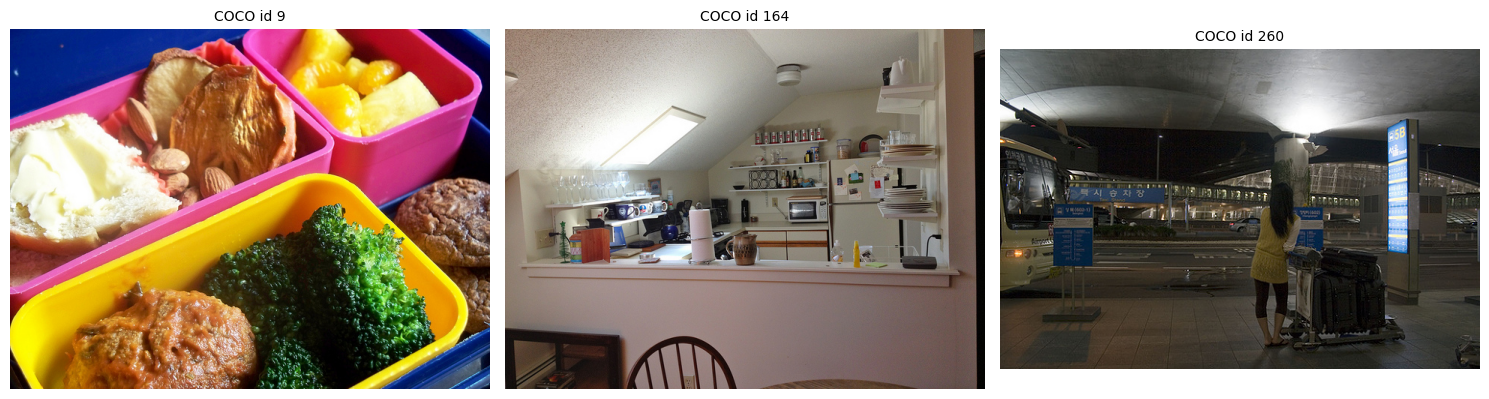

COCO id 9:
   - Closeup of bins of food that include broccoli and bread.
   - A meal is presented in brightly colored plastic trays.
   - there are containers filled with different kinds of foods
   - Colorful dishes holding meat, vegetables, fruit, and bread.
   - A bunch of trays that have different food.
COCO id 164:
   - A small kitchen with low a ceiling
   - A small kichen area with a sunlight and and angled ceiling.
   - an image of a kitchen loft style setting
   - a small kitchen with a lot of filled up shelves
   - A kitchen with a slanted ceiling and skylight.
COCO id 260:
   - A female traveler leaning on a luggage cart.
   - A woman is waiting with a cart full of luggage.
   - A woman next to a cart of luggage at a bus stop.
   - the woman is standing with her luggage
   - A woman wearing a yellow shirt standing next to luggage.


In [3]:
from PIL import Image

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, im, path in zip(axes, train_images[:3], paths["train"][:3]):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(f"COCO id {im['id']}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()
for im in train_images[:3]:
    print(f"COCO id {im['id']}:")
    for c in im["captions"]:
        print("   -", c)

## 3. Architecture of the captioning network

The diagram below is the complete network. The top row runs **once**, before any training; the bottom row is the model we train.

### 3.1 The CNN used for the pre-processing: InceptionV3

- **What it is.** InceptionV3 (Szegedy et al., 2015) is a convolutional network trained to classify the 1.28 million images of ImageNet into 1,000 classes. Its *Inception blocks* run convolutions of several sizes (1x1, 3x3, 5x5 factorised into smaller ones, pooling) in parallel and stack their outputs, so one block sees small and large patterns at the same time. It has 48 layers and 21.8 million parameters without its classification head.
- **What we take from it.** We remove the classification head (`include_top=False`) and keep the output of the last convolutional block (`mixed10`): for a 299x299 image it is an **8x8 grid of 2,048 numbers**. Each of the 64 cells describes one region of the image (about 37x37 pixels of the input, with a much larger field of view) with high-level features learned on ImageNet: textures, object parts, objects.
- **Why a pre-trained CNN (transfer learning).** 12,000 images are far too few to learn to see from scratch; ImageNet already taught InceptionV3 to recognise objects. Its weights are **frozen**: we only use it, we do not train it.
- **Why keep the grid and not one vector.** The pooled 2,048 vector (one per image) would lose *where* things are. With 64 regions the decoder can look at a different region for each word (attention, section 6).
- **Why compute it once and store it.** The 14,000 images go through InceptionV3 once (a few minutes), and the training then reads 64x2,048 numbers per image from disk instead of running 23 million parameters at every epoch. This only works because InceptionV3 is frozen.

### 3.2 The model we train: CNN encoder + RNN decoder with attention

- **CNN encoder.** One dense layer applied to each of the 64 regions (2,048 -> 512, ReLU). It adapts the generic ImageNet features to the captioning task. It is the trainable "CNN part": the convolutions themselves are in InceptionV3.
- **Initial state.** The mean of the 64 encoded regions goes through a dense layer (tanh) and becomes the first hidden state of the GRU: the decoder starts with a summary of the whole image.
- **RNN decoder.** The previous word goes through an **embedding** (index -> vector of 256 numbers, learned), then a **GRU** with 512 units. The GRU keeps a memory (hidden state) of the words already written; its gates decide, at each step, what to keep and what to update.
- **Attention.** At each step the GRU state is compared with the 64 regions (scaled dot product), a softmax turns the scores into 64 weights that sum to 1, and the **context** is the weighted mean of the regions: what the decoder looks at to write the next word.
- **Output.** GRU state and context are concatenated, normalised (layer normalization), mixed by a dense layer (tanh), and a last dense layer gives one score per word of the vocabulary (5,000). The softmax turns them into the probability of each word being the next one.

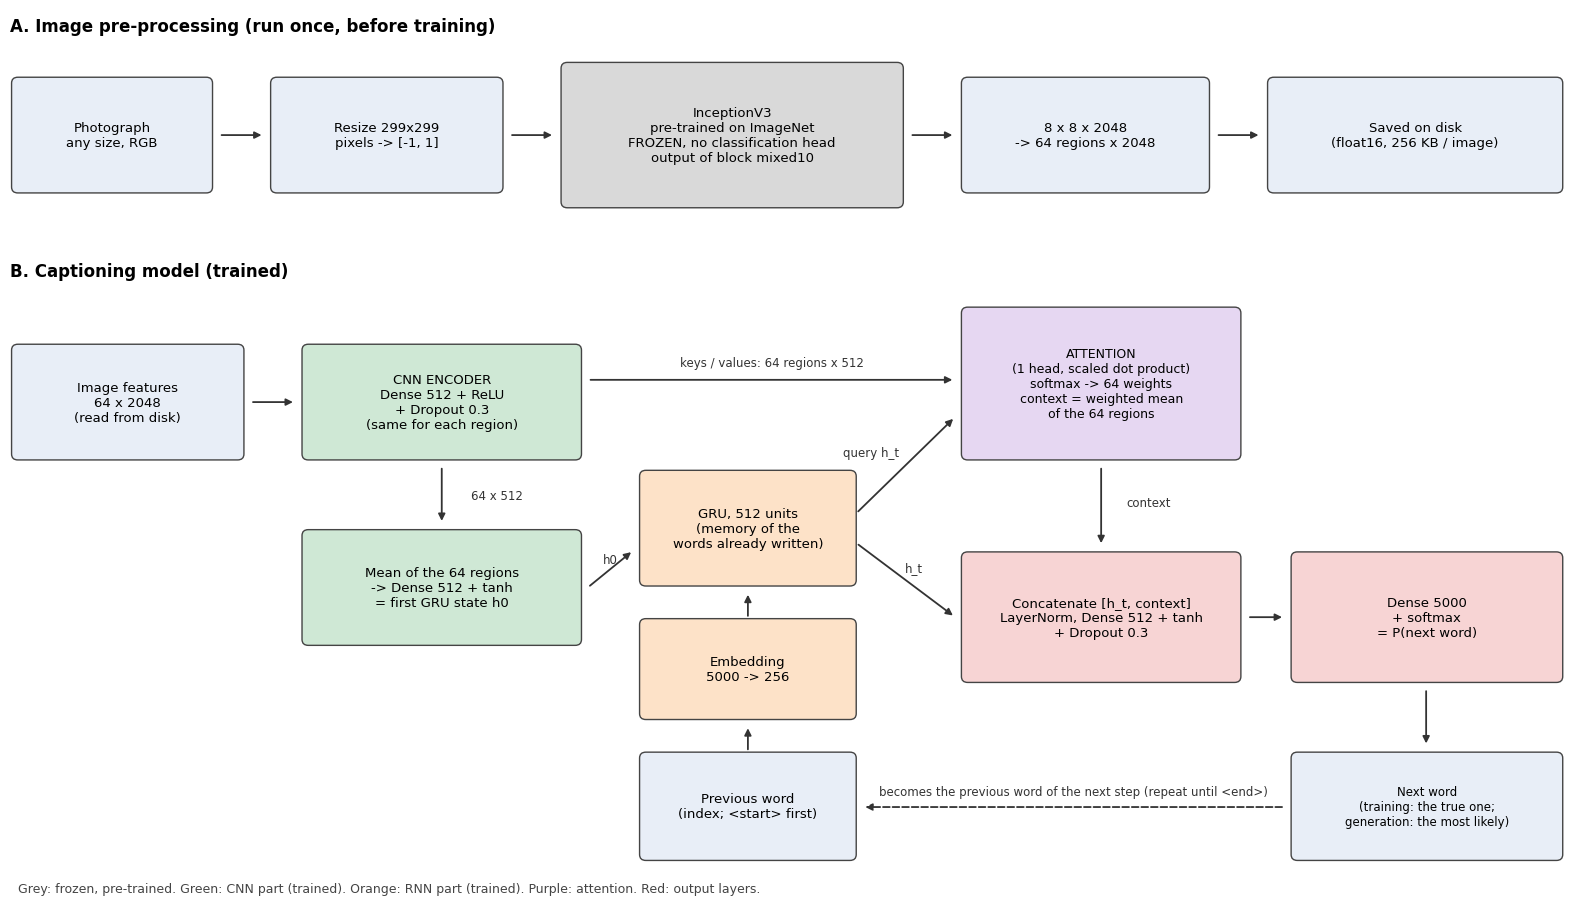

In [4]:
def draw_architecture():
    # Schematic diagram of the whole network (matplotlib only: no graphviz needed).
    fig, ax = plt.subplots(figsize=(16, 9.2))
    ax.set_xlim(0, 100); ax.set_ylim(0, 60); ax.axis("off")
    colours = {"data": "#e8eef7", "frozen": "#d9d9d9", "cnn": "#cfe8d5", "rnn": "#fde2c8", "att": "#e6d7f2", "out": "#f7d4d4"}

    def box(x, y, w, h, text, kind, size=9.5):
        ax.add_patch(matplotlib.patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.4",
                                                       fc=colours[kind], ec="#444444", lw=1))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=size)

    def arrow(x1, y1, x2, y2, text="", style="-|>", ls="-", rad=0.0, offset=(0, 0.9)):
        ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle=style, lw=1.3, color="#333333", ls=ls,
                                                             connectionstyle=f"arc3,rad={rad}"))
        if text:
            ax.text((x1 + x2) / 2 + offset[0], (y1 + y2) / 2 + offset[1], text, ha="center", fontsize=8.5, color="#333333")

    # Top row: pre-processing, run once.
    ax.text(0, 58.5, "A. Image pre-processing (run once, before training)", fontsize=12, weight="bold")
    box(0.5, 48, 12, 7, "Photograph\nany size, RGB", "data")
    box(17, 48, 14, 7, "Resize 299x299\npixels -> [-1, 1]", "data")
    box(35.5, 47, 21, 9, "InceptionV3\npre-trained on ImageNet\nFROZEN, no classification head\noutput of block mixed10", "frozen")
    box(61, 48, 15, 7, "8 x 8 x 2048\n-> 64 regions x 2048", "data")
    box(80.5, 48, 18, 7, "Saved on disk\n(float16, 256 KB / image)", "data")
    arrow(13.3, 51.5, 16.2, 51.5); arrow(31.8, 51.5, 34.7, 51.5); arrow(57.3, 51.5, 60.2, 51.5); arrow(76.8, 51.5, 79.7, 51.5)

    # Bottom: the trained model.
    ax.text(0, 42, "B. Captioning model (trained)", fontsize=12, weight="bold")
    box(0.5, 30, 14, 7, "Image features\n64 x 2048\n(read from disk)", "data")
    box(19, 30, 17, 7, "CNN ENCODER\nDense 512 + ReLU\n+ Dropout 0.3\n(same for each region)", "cnn")
    box(19, 17.5, 17, 7, "Mean of the 64 regions\n-> Dense 512 + tanh\n= first GRU state h0", "cnn")
    arrow(15.3, 33.5, 18.2, 33.5)
    arrow(27.5, 29.2, 27.5, 25.3, "64 x 512", offset=(3.5, -0.3))

    box(40.5, 3, 13, 6.5, "Previous word\n(index; <start> first)", "data")
    box(40.5, 12.5, 13, 6, "Embedding\n5000 -> 256", "rnn")
    box(40.5, 21.5, 13, 7, "GRU, 512 units\n(memory of the\nwords already written)", "rnn")
    arrow(47, 9.9, 47, 11.7); arrow(47, 18.9, 47, 20.7)
    arrow(36.8, 21, 39.7, 23.5, "h0", offset=(0, 0.4))
    arrow(53.9, 26, 60.2, 32.5, "query h_t", offset=(-2.2, 0.6))
    box(61, 30, 17, 9.5, "ATTENTION\n(1 head, scaled dot product)\nsoftmax -> 64 weights\ncontext = weighted mean\nof the 64 regions", "att", 9)
    arrow(36.8, 35, 60.2, 35, "keys / values: 64 regions x 512", offset=(0, 0.9))

    box(61, 15, 17, 8, "Concatenate [h_t, context]\nLayerNorm, Dense 512 + tanh\n+ Dropout 0.3", "out")
    arrow(69.5, 29.2, 69.5, 23.8, "context", offset=(3, 0))
    arrow(53.9, 24, 60.2, 19, "h_t", offset=(0.5, 0.6))
    box(82, 15, 16.5, 8, "Dense 5000\n+ softmax\n= P(next word)", "out")
    arrow(78.8, 19, 81.2, 19)
    box(82, 3, 16.5, 6.5, "Next word\n(training: the true one;\ngeneration: the most likely)", "data", 8.5)
    arrow(90.2, 14.2, 90.2, 10.3)
    arrow(81.2, 6.2, 54.3, 6.2, "becomes the previous word of the next step (repeat until <end>)", ls="--", offset=(0, 0.8))
    ax.text(0.5, 0.5, "Grey: frozen, pre-trained. Green: CNN part (trained). Orange: RNN part (trained). "
            "Purple: attention. Red: output layers.", fontsize=9, color="#444444")
    plt.tight_layout()
    plt.show()


draw_architecture()

## 4. Image pre-processing

Three steps for each image, in a `tf.data` pipeline that reads the images batch by batch (the 14,000 images are never all in memory):

1. **Read** the JPEG and force 3 colour channels (some COCO images are greyscale).
2. **Resize to 299x299**, the input size InceptionV3 was trained with (antialiasing on, to avoid artefacts when shrinking large photos).
3. **Scale the pixels from [0, 255] to [-1, 1]**: this is the scaling used when InceptionV3 was trained on ImageNet (`keras.applications.inception_v3.preprocess_input` does exactly `x / 127.5 - 1`). With another scaling the pre-trained filters would receive values they never saw.

Then InceptionV3 gives the 8x8x2048 grid, reshaped into 64 regions x 2048, and written to a `.npy` file per set. The features are stored as **float16** (half the size of float32: 3.1 GB instead of 6.3 GB for the training set); the cell checks that this rounding is negligible. The file is read with `mmap_mode="r"`: only the rows of the current batch are loaded in memory.

In [5]:
N_REGIONS, FEATURE_DIM = 64, 2048
FEATURES_DIR = Path(COCO_DIR) / "features"
FEATURES_DIR.mkdir(parents=True, exist_ok=True)


def read_for_inception(path):
    # Read one image -> 299x299x3 float32 in [-1, 1], the input InceptionV3 expects.
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, [CAPTION_IMG_SIZE, CAPTION_IMG_SIZE], antialias=True)   # float32 in [0, 255]
    img.set_shape([CAPTION_IMG_SIZE, CAPTION_IMG_SIZE, 3])
    return img / 127.5 - 1.0   # = keras.applications.inception_v3.preprocess_input


inception = keras.applications.InceptionV3(include_top=False, weights="imagenet",
                                           input_shape=(CAPTION_IMG_SIZE, CAPTION_IMG_SIZE, 3))
inception.trainable = False
print(f"InceptionV3 without its head: {inception.count_params():,} parameters (frozen), output {inception.output_shape}")


@tf.function   # compiled once: much faster and lighter on GPU memory than running the layers one by one
def inception_features(batch):
    # Batch of pre-processed images -> (batch, 64, 2048) float32.
    return tf.reshape(inception(batch, training=False), (-1, N_REGIONS, FEATURE_DIM))


def extract_features(name, image_paths, batch_size=16):   # 16: fits a 2 GB GPU
    # Features of every image of a set, computed once and cached on disk (read with memory mapping).
    # The file name contains a hash of the list of paths: another subset never reuses a wrong file.
    key = hashlib.md5("|".join(image_paths).encode()).hexdigest()[:10]
    out = FEATURES_DIR / f"inceptionv3_{name}_{len(image_paths)}_{key}.npy"
    done = out.with_suffix(".done")   # written last: an interrupted extraction is started again
    if not done.exists():
        t0 = time.time()
        feats = np.lib.format.open_memmap(out, mode="w+", dtype=np.float16,
                                          shape=(len(image_paths), N_REGIONS, FEATURE_DIM))
        ds = (tf.data.Dataset.from_tensor_slices(image_paths)
              .map(read_for_inception, num_parallel_calls=tf.data.AUTOTUNE)
              .batch(batch_size).prefetch(tf.data.AUTOTUNE))
        i = 0
        for batch in ds:
            f = inception_features(batch).numpy()
            feats[i:i + len(f)] = f.astype(np.float16)
            i += len(f)
        feats.flush()
        del feats
        done.touch()
        print(f"{name}: features of {len(image_paths):,} images computed in {time.time() - t0:.0f} s")
    return np.load(out, mmap_mode="r")


features = {name: extract_features(name, p) for name, p in paths.items()}
for name, f in features.items():
    print(f"{name:5s}: {f.shape} {f.dtype} | {f.nbytes / 1e9:.2f} GB on disk")

# float16 check: the same images in float32, compared with what is stored.
check = inception_features(tf.stack([read_for_inception(p) for p in paths["val"][:16]])).numpy()
stored = features["val"][:16].astype(np.float32)
print(f"float16 rounding: max abs error {np.abs(check - stored).max():.4f} | "
      f"relative error of the norm {np.linalg.norm(check - stored) / np.linalg.norm(check):.1e} | "
      f"features in [{check.min():.1f}, {check.max():.1f}], {100 * (check == 0).mean():.0f} % zeros (ReLU)")

E0000 00:00:1792409935.984554  366288 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792409935.984810  366288 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792409935.984995  366288 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792409936.195406  366288 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792409936.195646  366288 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792409936.195854  366288 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.


InceptionV3 without its head: 21,802,784 parameters (frozen), output (None, 8, 8, 2048)
train: (12000, 64, 2048) float16 | 3.15 GB on disk
val  : (1000, 64, 2048) float16 | 0.26 GB on disk
test : (1000, 64, 2048) float16 | 0.26 GB on disk


float16 rounding: max abs error 0.0075 | relative error of the norm 2.1e-04 | features in [0.0, 25.8], 61 % zeros (ReLU)


## 5. Text pre-processing

The network works on numbers, so each caption becomes a list of word indexes:

1. **Cleaning.** Lower case, and keep only the words made of letters (punctuation and digits are dropped; "t-shirt" becomes "t shirt").
2. **Start and end markers.** `<start>` is added in front (the first input of the decoder: it has to start from something) and `<end>` at the end (the network learns to stop by predicting it).
3. **Vocabulary: the most frequent words.** We count the words of the **training** captions only and keep the 4,996 most frequent ones, plus 4 special tokens (`<pad>`, `<unk>`, `<start>`, `<end>`): 5,000 words. Rare words (a few occurrences each) cannot be learned anyway; they become `<unk>` (unknown).
4. **Word indexes.** Each word gets its rank in the vocabulary (`<pad>` = 0, `<unk>` = 1, `<start>` = 2, `<end>` = 3, then 4 = the most frequent word, ...).
5. **Padding.** All the sequences get the same length (`MAX_LEN` = 22: `<start>`, up to 20 words, `<end>`), completed with `<pad>` = 0, so that they fit in one tensor. The few captions longer than 20 words are not used for training (they stay as references in the evaluation).
6. **Input and target, shifted by one.** For training, the input of the decoder is the sequence without its last token and the target is the sequence without its first one: at each position the network must predict the **next** word. Giving the true previous word (not the predicted one) during training is called *teacher forcing*.

In [6]:
PAD, UNK, START, END = "<pad>", "<unk>", "<start>", "<end>"
VOCAB_SIZE = 5000
MAX_WORDS = 20
MAX_LEN = MAX_WORDS + 2   # <start> + words + <end>


def clean(caption):
    # Lower case, words made of letters only.
    return re.findall(r"[a-z]+", caption.lower())


word_counts = Counter(w for im in train_images for c in im["captions"] for w in clean(c))
# Sorted by count, then alphabetically: the same vocabulary on every machine (ties are frequent).
by_frequency = sorted(word_counts, key=lambda w: (-word_counts[w], w))
vocab = [PAD, UNK, START, END] + by_frequency[:VOCAB_SIZE - 4]
word_index = {w: i for i, w in enumerate(vocab)}

covered = sum(word_counts[w] for w in vocab[4:])
print(f"Distinct words in the training captions: {len(word_counts):,}; kept: {len(vocab) - 4:,} "
      f"(+4 special tokens) = {len(vocab):,}")
print(f"They cover {100 * covered / sum(word_counts.values()):.2f} % of the word occurrences; the least frequent "
      f"kept word ('{vocab[-1]}') appears {word_counts[vocab[-1]]} times")
print("Most frequent words:", ", ".join(vocab[4:24]))


def encode(words):
    # Word list -> MAX_LEN indexes: <start>, words (unknown -> <unk>), <end>, then <pad> = 0.
    ids = [word_index[START]] + [word_index.get(w, word_index[UNK]) for w in words] + [word_index[END]]
    return ids + [word_index[PAD]] * (MAX_LEN - len(ids))


def make_pairs(ims):
    # One (image number, encoded caption) pair per caption of at most MAX_WORDS words.
    img_idx, seqs = [], []
    for i, im in enumerate(ims):
        for c in im["captions"]:
            words = clean(c)
            if 0 < len(words) <= MAX_WORDS:
                img_idx.append(i)
                seqs.append(encode(words))
    return np.array(img_idx, np.int32), np.array(seqs, np.int32)


pairs = {name: make_pairs(images[name]) for name in ("train", "val")}
for name, (img_idx, seqs) in pairs.items():
    n_all = sum(len(im["captions"]) for im in images[name])
    print(f"{name:5s}: {len(seqs):,} (image, caption) pairs, {n_all - len(seqs)} captions longer than "
          f"{MAX_WORDS} words left out ({100 * (n_all - len(seqs)) / n_all:.1f} %) | tensor {seqs.shape}")

Distinct words in the training captions: 10,312; kept: 4,996 (+4 special tokens) = 5,000
They cover 98.95 % of the word occurrences; the least frequent kept word ('aimed') appears 2 times
Most frequent words: a, on, of, the, in, with, and, is, man, to, sitting, an, two, at, people, are, standing, next, white, woman


train: 59,657 (image, caption) pairs, 380 captions longer than 20 words left out (0.6 %) | tensor (59657, 22)
val  : 4,982 (image, caption) pairs, 21 captions longer than 20 words left out (0.4 %) | tensor (4982, 22)


### One caption, step by step

In [7]:
example = train_images[0]["captions"][0]
words = clean(example)
ids = encode(words)
print("raw caption :", example)
print("cleaned     :", words)
print("with markers:", [START] + words + [END])
print("indexes     :", ids)
print("decoder input  (all but the last):", ids[:-1])
print("decoder target (all but the first):", ids[1:])
print("back to words:", " ".join(vocab[i] for i in ids))

raw caption : Closeup of bins of food that include broccoli and bread.
cleaned     : ['closeup', 'of', 'bins', 'of', 'food', 'that', 'include', 'broccoli', 'and', 'bread']
with markers: ['<start>', 'closeup', 'of', 'bins', 'of', 'food', 'that', 'include', 'broccoli', 'and', 'bread', '<end>']
indexes     : [2, 767, 6, 2349, 6, 63, 26, 1916, 234, 10, 418, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
decoder input  (all but the last): [2, 767, 6, 2349, 6, 63, 26, 1916, 234, 10, 418, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0]
decoder target (all but the first): [767, 6, 2349, 6, 63, 26, 1916, 234, 10, 418, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
back to words: <start> closeup of bins of food that include broccoli and bread <end> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad>


### The training pipeline

`tf.data` yields batches of 64 `((image features, input words), target words)`. Only the **pairs** (image number, caption) are shuffled; the features of the batch are read from the memory-mapped file and converted to float32 at that moment. With 5 captions per image, one epoch sees each training image about 5 times, once with each caption.

In [8]:
BATCH = 64


def make_caption_dataset(feats, img_idx, seqs, training=False):
    ds = tf.data.Dataset.from_tensor_slices((img_idx, seqs))
    if training:
        ds = ds.shuffle(len(seqs), seed=SEED, reshuffle_each_iteration=True)   # new order at every epoch
    ds = ds.batch(BATCH)

    def load(idx, seq):
        # Read the features of the batch from disk (float16 -> float32).
        f = tf.numpy_function(lambda i: feats[i].astype(np.float32), [idx], tf.float32)
        f.set_shape([None, N_REGIONS, FEATURE_DIM])
        # Teacher forcing: input = sequence without its last token, target = sequence without its first.
        return (f, seq[:, :-1]), seq[:, 1:]

    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)


train_ds = make_caption_dataset(features["train"], *pairs["train"], training=True)
val_ds = make_caption_dataset(features["val"], *pairs["val"])
(f, words_in), words_out = next(iter(val_ds))
print("one batch: features", f.shape, f.dtype, "| input words", words_in.shape, "| target words", words_out.shape)
print(f"{len(pairs['train'][1]) // BATCH + 1} batches (iterations) per epoch")

one batch: features (64, 64, 2048) <dtype: 'float32'> | input words (64, 21) | target words (64, 21)
933 batches (iterations) per epoch


## 6. The code of the CNN and of the RNN

`build_captioner()` builds the network of section 3.2 with the Keras functional API. It returns two models that **share the same layers and weights**: `captioner` (outputs the word scores, used for training) and `captioner_attention` (also outputs the attention weights, used to draw them in section 9).

**Shapes**, for a batch of B images and captions of T = 21 positions: features (B, 64, 2048) -> encoded regions (B, 64, 512); words (B, 21) -> embeddings (B, 21, 256) -> GRU states (B, 21, 512) -> context (B, 21, 512) -> scores (B, 21, 5000).

The GRU processes the 21 positions in order, but during training all of them are computed in one call, because the true previous words are known (teacher forcing). The attention is computed for each position from the GRU state of that position only, so the prediction at position t never sees the words after t.

**Loss: masked cross-entropy.** For each position, the cross-entropy between the 5,000 scores and the true next word (softmax included, `from_logits=True`). The `<pad>` positions are not real words, so they are **masked**: the loss is the mean over the real words only. Without the mask, a large part of the loss would be "predict `<pad>` after `<end>`", which is trivial. The **masked accuracy** is the share of real words where the most likely word is the true one. **Optimizer:** Adam, learning rate 1e-3, with **gradient clipping** (`clipnorm=1.0`). **Dropout** 0.3 after the encoder and before the output, against overfitting.

**Two safeguards, added after a failed first run.** Our first training on the 12,000 images stalled in the first epoch: the loss stayed at 5.5 and the model wrote "a" for every word (14 % accuracy, the share of "a" among the words). The same code learned normally on 2,000 images, so the data was right and the training had become unstable. The concatenated vector mixes the GRU state (between -1 and 1) with the attention context (built from InceptionV3 features up to about 24). We measured it on the saved weights of that run: its values were 44 on average and up to 613, so **100 % of the outputs of the next `tanh` were stuck at -1 or +1**, in the flat part where the gradient is almost zero: the network could not learn any more. **Layer normalization** rescales this vector before the `tanh`, and **gradient clipping** limits the size of one update, a classic protection for RNNs. With both, the same training reaches a validation accuracy of 44 % after 2 epochs.

In [9]:
EMBED_DIM, UNITS, ATT_DIM, DROPOUT = 256, 512, 256, 0.3


def masked_loss(y_true, y_pred):
    # Cross-entropy on the real words only (<pad> = 0 is ignored).
    loss = keras.losses.sparse_categorical_crossentropy(y_true, y_pred, from_logits=True)
    mask = tf.cast(tf.not_equal(y_true, 0), loss.dtype)
    return tf.reduce_sum(loss * mask) / tf.reduce_sum(mask)


def masked_accuracy(y_true, y_pred):
    # Share of the real words where the most likely word is the right one.
    y_true = tf.cast(y_true, tf.int64)
    mask = tf.cast(tf.not_equal(y_true, 0), tf.float32)
    hit = tf.cast(tf.equal(tf.argmax(y_pred, axis=-1), y_true), tf.float32)
    return tf.reduce_sum(hit * mask) / tf.reduce_sum(mask)


def build_captioner():
    # CNN encoder + GRU decoder with attention. Returns (training model, same model + attention weights).
    keras.utils.set_random_seed(SEED)   # same initial weights at every run
    features_in = keras.Input((N_REGIONS, FEATURE_DIM), name="image_features")
    words_in = keras.Input((MAX_LEN - 1,), dtype="int32", name="previous_words")

    # TimeDistributed(Dense): the SAME dense layer applied to each region (or each word position) separately.
    # (A plain Dense on a 3-D tensor gives the same result but its gradient needs 64x more GPU memory.)

    # ---- CNN part (encoder): the same dense layer on each of the 64 regions, 2048 -> 512.
    regions = keras.layers.TimeDistributed(keras.layers.Dense(UNITS, activation="relu"), name="encoder_dense")(features_in)
    regions = keras.layers.Dropout(DROPOUT, name="encoder_dropout")(regions)

    # ---- First GRU state: a summary of the whole image (mean of the regions).
    summary = keras.layers.GlobalAveragePooling1D(name="mean_of_regions")(regions)
    h0 = keras.layers.Dense(UNITS, activation="tanh", name="initial_state")(summary)

    # ---- RNN part (decoder).
    x = keras.layers.Embedding(VOCAB_SIZE, EMBED_DIM, name="embedding")(words_in)   # index -> vector of 256
    h = keras.layers.GRU(UNITS, return_sequences=True, name="gru")(x, initial_state=h0)  # one state per position

    # ---- Attention: each GRU state (query) looks at the 64 regions (keys and values).
    # One head = scaled dot product: softmax(q . k / sqrt(ATT_DIM)) over the regions, after learned projections.
    attention = keras.layers.MultiHeadAttention(num_heads=1, key_dim=ATT_DIM, name="attention")
    context, scores = attention(query=h, value=regions, key=regions, return_attention_scores=True)

    # ---- Output: one score per word of the vocabulary (the softmax is in the loss).
    x = keras.layers.Concatenate(name="state_and_context")([h, context])
    # LayerNormalization: brings each vector back to mean 0 / std 1 (then a learned scale and shift).
    # Without it the context, built from large ImageNet features, saturates the tanh below and training stalls.
    x = keras.layers.LayerNormalization(name="normalise")(x)
    x = keras.layers.TimeDistributed(keras.layers.Dense(UNITS, activation="tanh"), name="combine")(x)
    x = keras.layers.Dropout(DROPOUT, name="output_dropout")(x)
    logits = keras.layers.TimeDistributed(keras.layers.Dense(VOCAB_SIZE), name="next_word_scores")(x)

    model = keras.Model([features_in, words_in], logits, name="captioner")
    # clipnorm=1.0: if the gradient is very large (it happens with RNNs), it is scaled down to a norm of 1.
    model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0), loss=masked_loss, metrics=[masked_accuracy])
    with_attention = keras.Model([features_in, words_in], [logits, scores], name="captioner_attention")
    return model, with_attention


captioner, captioner_attention = build_captioner()
captioner.summary()

Model: "captioner"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_features      │ (None, 64, 2048)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dense       │ (None, 64, 512)   │  1,049,088 │ image_features[0… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dropout     │ (None, 64, 512)   │          0 │ encoder_dense[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ previous_words      │ (None, 21)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mean_of_regions     │ (None, 512)       │          0 │ encoder_dropout[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 21, 256)   │  1,280,000 │ previous_words[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ initial_state       │ (None, 512)       │    262,656 │ mean_of_regions[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 21, 512)   │  1,182,720 │ embedding[0][0],  │
│                     │                   │            │ initial_state[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, 21, 512), │    525,568 │ encoder_dropout[… │
│ (MultiHeadAttentio… │ (None, 1, 21,     │            │ gru[0][0],        │
│                     │ 21)]              │            │ encoder_dropout[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ state_and_context   │ (None, 21, 1024)  │          0 │ gru[0][0],        │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalise           │ (None, 21, 1024)  │      2,048 │ state_and_contex… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combine             │ (None, 21, 512)   │    524,800 │ normalise[0][0]   │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_dropout      │ (None, 21, 512)   │          0 │ combine[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_word_scores    │ (None, 21, 5000)  │  2,565,000 │ output_dropout[0… │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,391,880 (28.20 MB)

 Trainable params: 7,391,880 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Parameters by part of the network (the frozen InceptionV3 is not in this model).
parts = {
    "CNN encoder (regions + initial state)": ["encoder_dense", "initial_state"],
    "RNN decoder (embedding + GRU)": ["embedding", "gru"],
    "Attention": ["attention"],
    "Output (normalise + combine + next word)": ["normalise", "combine", "next_word_scores"],
}
counts = {part: sum(captioner.get_layer(n).count_params() for n in names) for part, names in parts.items()}
assert sum(counts.values()) == captioner.count_params()
counts["Total trained"] = captioner.count_params()
counts["InceptionV3 (frozen, run once)"] = inception.count_params()
pd.Series(counts, name="parameters").map("{:,}".format).to_frame()

,parameters
CNN encoder (regions + initial state),"1,311,744"
RNN decoder (embedding + GRU),"2,462,720"
Attention,"525,568"
Output (normalise + combine + next word),"3,091,848"
Total trained,"7,391,880"
"InceptionV3 (frozen, run once)","21,802,784"


## 7. Training

### Settings

- **Data:** the training pairs (image, caption), shuffled at every epoch, batches of 64. One **epoch** is one pass over all the pairs; one **iteration** is one batch, i.e. one update of the weights.
- **Loss / metric:** masked cross-entropy / masked accuracy (section 6). **Optimizer:** Adam, learning rate 1e-3.
- **Early stopping:** we stop when the validation loss has not improved for `PATIENCE` = 3 epochs and keep the best weights (`MAX_EPOCHS` is only an upper bound). The validation captions are never used for anything else.
- **Saved weights:** written to `models/d3_captioner_<date>.weights.h5` as soon as the validation loss improves, with the history and the vocabulary next to them. If they exist, the notebook reloads them instead of training again (`RETRAIN = True` to train again). The vocabulary is checked on reload: weights trained with another vocabulary would give nonsense.

In [11]:
MODELS = Path("models")
MODELS.mkdir(exist_ok=True)
MAX_EPOCHS, PATIENCE = 30, 3
RETRAIN = False   # True: ignore the saved weights and train again


def train_or_load(name, model):
    # Train `model` (or reload its latest saved weights) and return its history.
    saved = sorted(MODELS.glob(f"d3_{name}_[0-9]*.weights.h5"))   # the timestamp sorts alphabetically
    if saved and not RETRAIN:
        weights = saved[-1]
        saved_vocab = json.loads(weights.with_name(weights.name.replace(".weights.h5", "_vocab.json")).read_text())
        assert saved_vocab == vocab, "these weights were trained with another vocabulary: set RETRAIN = True"
        model.load_weights(weights)
        history = json.loads(weights.with_name(weights.name.replace(".weights.h5", "_history.json")).read_text())
        print(f"Reloaded {weights.name} ({len(history['loss'])} epochs, trained in "
              f"{history['seconds'] / 60:.0f} min), no training.")
        return history

    weights = MODELS / f"d3_{name}_{datetime.now():%Y%m%d_%H%M%S}.weights.h5"
    weights.with_name(weights.name.replace(".weights.h5", "_vocab.json")).write_text(json.dumps(vocab))
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(weights, monitor="val_loss", save_best_only=True, save_weights_only=True),
    ]
    t0 = time.time()
    fit = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, callbacks=callbacks, verbose=2)
    history = {k: [float(v) for v in vals] for k, vals in fit.history.items()}
    history["seconds"] = time.time() - t0
    weights.with_name(weights.name.replace(".weights.h5", "_history.json")).write_text(json.dumps(history))
    print(f"Trained {len(history['loss'])} epochs in {history['seconds'] / 60:.0f} min, best weights in {weights.name}")
    return history


history = train_or_load("captioner", captioner)

Reloaded d3_captioner_20261019_122328.weights.h5 (7 epochs, trained in 7 min), no training.


/home/utilisateur/leyenda/.venv/lib/python3.10/site-packages/keras/src/saving/saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


### Training curves

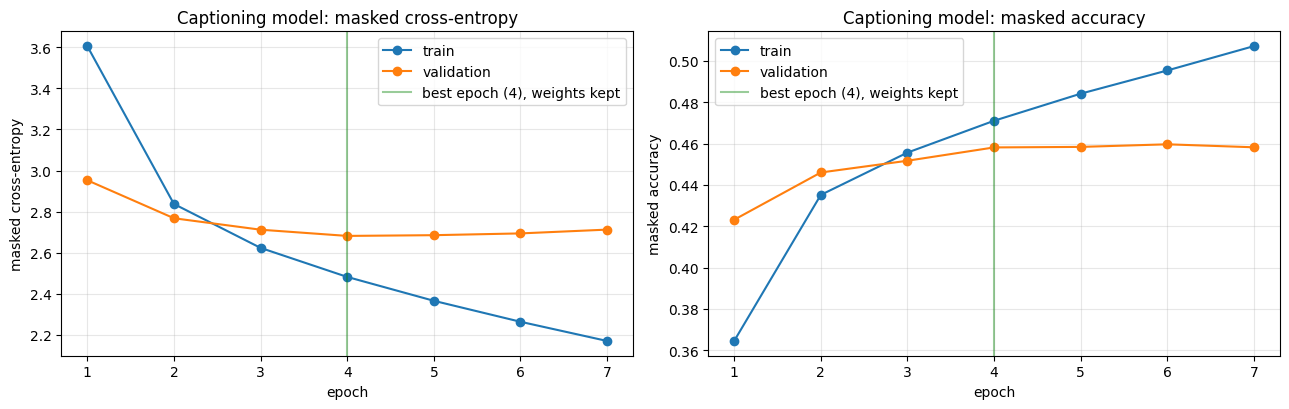

Best epoch 4: train loss 2.482 | val loss 2.682 (perplexity 14.6) | train accuracy 0.471 | val accuracy 0.458


In [12]:
epochs = np.arange(1, len(history["loss"]) + 1)
best = int(np.argmin(history["val_loss"]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, metric, label in [(axes[0], "loss", "masked cross-entropy"), (axes[1], "masked_accuracy", "masked accuracy")]:
    ax.plot(epochs, history[metric], marker="o", label="train")
    ax.plot(epochs, history[f"val_{metric}"], marker="o", label="validation")
    ax.axvline(best + 1, color="green", alpha=0.4, label=f"best epoch ({best + 1}), weights kept")
    ax.set_xlabel("epoch"); ax.set_ylabel(label); ax.set_title(f"Captioning model: {label}")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()
print(f"Best epoch {best + 1}: train loss {history['loss'][best]:.3f} | val loss {history['val_loss'][best]:.3f} "
      f"(perplexity {np.exp(history['val_loss'][best]):.1f}) | train accuracy {history['masked_accuracy'][best]:.3f} | "
      f"val accuracy {history['val_masked_accuracy'][best]:.3f}")

**Reading (numbers of our run, seed 42).**

- **Best epoch: 4.** The validation loss goes from 2.95 to 2.68 (perplexity 14.6: on average the model hesitates as if it had to choose between about 15 words), then rises again while the training loss keeps falling (2.48 at epoch 4, 2.17 at epoch 7). From epoch 5 the model learns the training captions by heart instead of things that generalise: this is **overfitting**, and early stopping kept the weights of epoch 4. Training took 7 epochs, 7 minutes.
- **Train above validation at the start** (epochs 1 and 2): normal, the training loss is the mean over an epoch during which the weights improve, and dropout is only active during training.
- **Accuracy 45.8 %** on validation: almost one next word in two is exactly the human one. It looks low, but many words have equivalents ("man" / "person", "sitting" / "standing" in some images) that this measure counts as wrong. The captions themselves are judged in section 8.
- **Why it overfits so early.** 7.4 million parameters against 12,000 images: the model has enough capacity to memorise their 60,000 captions. More images is the most direct fix (section 11).

## 8. Writing captions and measuring them

### 8.1 Generation (greedy decoding)

After training there is no true previous word any more. We start from `<start>`, take the **most likely** word, give it back as the next input, and repeat until `<end>` (or 21 words). `<pad>`, `<unk>` and `<start>` are never chosen. All the test images are processed together, batch by batch. Because the GRU only looks backwards, running the model on the sequence written so far gives exactly the prediction of the next position.

### 8.2 BLEU, and two references to read it

**BLEU** (Papineni et al., 2002) is the usual score for generated sentences: it counts how many groups of *n* consecutive words (n-grams) of the generated caption appear in the human captions of the same image (counts clipped, so that repeating a correct word is not rewarded), for n = 1 to 4, and takes their geometric mean. A **brevity penalty** lowers the score of captions shorter than the references. BLEU-1 measures the choice of words, BLEU-4 also the word order. It is computed on the whole test set (corpus BLEU), with our own 25-line implementation below. It follows the original definition and gives the same numbers as `nltk.translate.bleu_score.corpus_bleu` (checked on random corpora), except for captions shorter than *n* words, which NLTK counts as one n-gram.

A BLEU score alone means little, so we compare with two references, all computed on the **same test images and against the same human captions**:

- **Human:** one of the human captions (the first one) scored against the others. It shows how much two people agree: a model cannot be expected to do much better.
- **Nearest training image (retrieval):** no RNN at all. We find the training image whose InceptionV3 features are the most similar (cosine of the mean of the 64 regions) and copy its first caption. If the model does not beat this, the RNN learned nothing more than "similar images, similar captions".

To keep the three rows comparable, the first human caption of each test image is kept aside and every method is scored against the **remaining ones** (4 or more per image).

In [13]:
BANNED = [word_index[PAD], word_index[UNK], word_index[START]]


def generate(feats, batch_size=125):
    # Greedy decoding for a (n, 64, 2048) array of features. Returns the captions (word lists) and the index sequences.
    captions, sequences = [], []
    for s in range(0, len(feats), batch_size):
        f = np.asarray(feats[s:s + batch_size], dtype=np.float32)
        n = len(f)
        seq = np.zeros((n, MAX_LEN - 1), np.int32)
        seq[:, 0] = word_index[START]
        out = np.zeros((n, MAX_LEN - 1), np.int32)
        finished = np.zeros(n, bool)
        for t in range(MAX_LEN - 1):
            scores = captioner.predict_on_batch([f, seq])[:, t]   # (n, VOCAB_SIZE) for position t
            scores[:, BANNED] = -np.inf
            nxt = scores.argmax(axis=-1)
            out[:, t] = np.where(finished, word_index[PAD], nxt)
            finished |= nxt == word_index[END]
            if finished.all():
                break
            if t + 1 < MAX_LEN - 1:
                seq[:, t + 1] = nxt
        for row in out:
            words = []
            for i in row:
                if i in (word_index[END], word_index[PAD]):
                    break
                words.append(vocab[i])
            captions.append(words)
        sequences.append(seq)
    return captions, np.concatenate(sequences)


def corpus_bleu(references, hypotheses, max_n=4):
    # references: one list of word lists per image; hypotheses: one word list per image. Returns BLEU-1..max_n.
    clipped, total = np.zeros(max_n), np.zeros(max_n)
    hyp_len = ref_len = 0
    for refs, hyp in zip(references, hypotheses):
        hyp_len += len(hyp)
        # Reference length for the brevity penalty: the closest one (the shorter one in case of a tie).
        ref_len += min((abs(len(r) - len(hyp)), len(r)) for r in refs)[1]
        for n in range(1, max_n + 1):
            grams = Counter(tuple(hyp[i:i + n]) for i in range(len(hyp) - n + 1))
            max_in_ref = Counter()
            for r in refs:
                for g, c in Counter(tuple(r[i:i + n]) for i in range(len(r) - n + 1)).items():
                    max_in_ref[g] = max(max_in_ref[g], c)
            clipped[n - 1] += sum(min(c, max_in_ref[g]) for g, c in grams.items())
            total[n - 1] += max(len(hyp) - n + 1, 0)
    brevity = 1.0 if hyp_len > ref_len else np.exp(1 - ref_len / max(hyp_len, 1))
    with np.errstate(divide="ignore"):
        log_p = np.log(clipped / np.maximum(total, 1))
    return {f"BLEU-{n}": float(brevity * np.exp(log_p[:n].mean())) for n in range(1, max_n + 1)}


t0 = time.time()
test_captions, test_sequences = generate(features["test"])
print(f"{len(test_captions)} test captions generated in {time.time() - t0:.0f} s")

1000 test captions generated in 30 s


In [14]:
def mean_region_features(feats, chunk=500):
    # Mean of the 64 regions of each image, L2-normalised (for the cosine similarity).
    m = np.concatenate([feats[s:s + chunk].astype(np.float32).mean(axis=1) for s in range(0, len(feats), chunk)])
    return m / np.linalg.norm(m, axis=1, keepdims=True)


train_mean, test_mean = mean_region_features(features["train"]), mean_region_features(features["test"])
nearest = (test_mean @ train_mean.T).argmax(axis=1)   # most similar training image, for each test image
retrieval_captions = [clean(train_images[j]["captions"][0]) for j in nearest]

held_out = [clean(im["captions"][0]) for im in test_images]           # the "human" row
references = [[clean(c) for c in im["captions"][1:]] for im in test_images]
train_caption_set = {" ".join(clean(c)) for im in train_images for c in im["captions"]}

rows = {}
for name, hyps in [("Human (one caption vs the others)", held_out),
                   ("Nearest training image (retrieval)", retrieval_captions),
                   ("Our model (CNN + GRU + attention)", test_captions)]:
    row = corpus_bleu(references, hyps)
    row["mean length (words)"] = np.mean([len(h) for h in hyps])
    row["distinct captions"] = len({" ".join(h) for h in hyps})
    row["copied from training (%)"] = 100 * np.mean([" ".join(h) in train_caption_set for h in hyps])
    rows[name] = row
results = pd.DataFrame(rows).T
print(f"Test set: {len(test_images)} COCO val2017 images, scored against {sum(map(len, references)):,} human captions")
results.style.format({**{f"BLEU-{n}": "{:.3f}" for n in range(1, 5)}, "mean length (words)": "{:.1f}",
                      "distinct captions": "{:.0f}", "copied from training (%)": "{:.1f}"})

Test set: 1000 COCO val2017 images, scored against 4,002 human captions


,BLEU-1,BLEU-2,BLEU-3,BLEU-4,mean length (words),distinct captions,copied from training (%)
Human (one caption vs the others),0.641,0.445,0.301,0.204,10.4,998,3.5
Nearest training image (retrieval),0.459,0.266,0.158,0.097,10.5,900,100.0
Our model (CNN + GRU + attention),0.617,0.420,0.274,0.179,9.5,750,9.9


**Reading (numbers of our run).**

- **The model is far above the retrieval baseline**: BLEU-4 0.179 against 0.097 (+85 %), BLEU-1 0.617 against 0.459. The RNN does more than "similar image, similar caption": it composes captions adapted to each image (only 9.9 % of its captions are copies of a training caption).
- **It is close to the human row** (BLEU-4 0.179 against 0.204, BLEU-1 0.617 against 0.641). This does **not** mean that its captions are as good as human ones. BLEU rewards the most usual wording: a person who writes something specific ("two very sexy women in bikinis", section 9) is penalised because the others did not say it, while the model learned to say the most likely thing. The last columns show it: the model writes shorter captions (9.5 words against 10.4) and is less varied (750 different captions for 1,000 images, against 998).
- **For comparison only:** published models trained on the whole of COCO (118,000 images) report BLEU-4 around 0.25 to 0.30 against 5 references. Our numbers are not directly comparable (12,000 images, 4 references, our own split), but the order of magnitude is consistent.

## 9. Test examples

### 9.1 Captioned test images

Eight test images drawn at random (seed 42, not chosen by hand), with the caption of the model and one human caption.

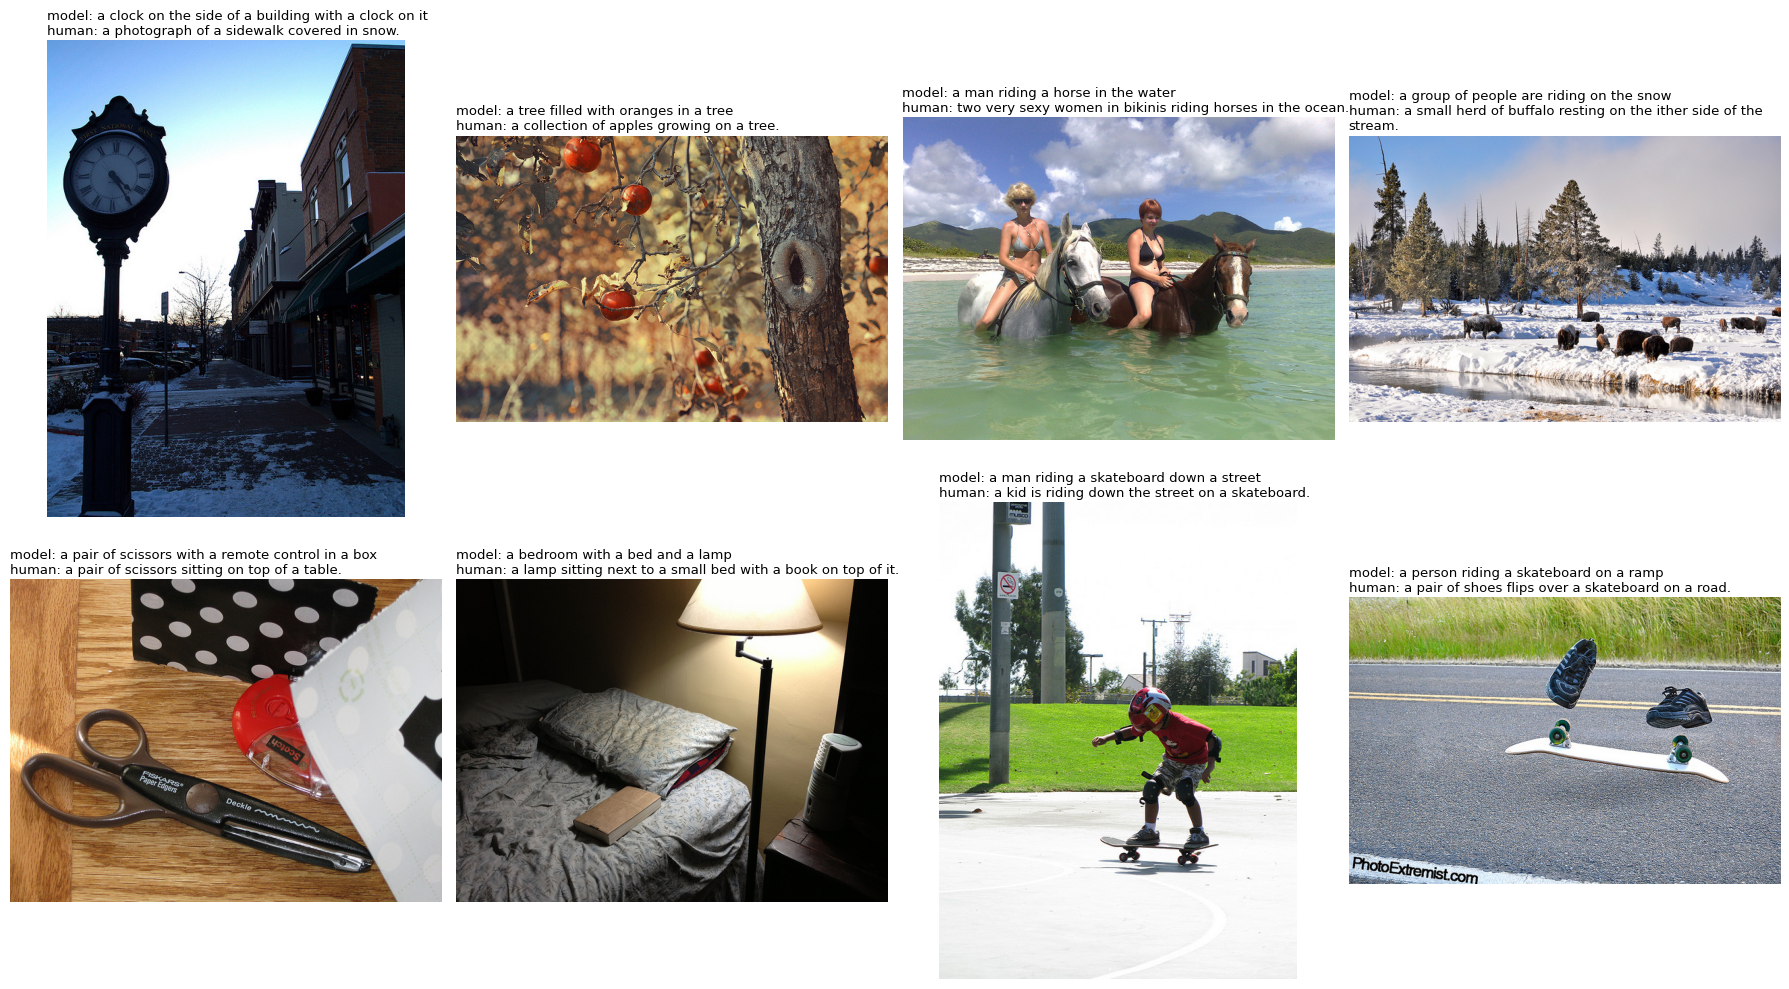

In [15]:
rng = np.random.default_rng(SEED)
shown = sorted(rng.choice(len(test_images), 8, replace=False))
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
for ax, i in zip(axes.ravel(), shown):
    ax.imshow(Image.open(paths["test"][i]).convert("RGB"))
    ax.set_title(f"model: {' '.join(test_captions[i])}\nhuman: {test_images[i]['captions'][0].strip().lower()}",
                 fontsize=9.5, loc="left", wrap=True)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Reading.** The main object or the scene is right in 6 of the 8 images (clock and building, tree with fruit, horse in the water, scissors, bedroom with a bed and a lamp, skateboard in the street). The errors are typical of this kind of model:

- **The most frequent training situations win.** The buffalo in the snow become "a group of people are riding on the snow" (snow in COCO is mostly skiing), and the flying shoes become "a person riding a skateboard on a ramp", the usual skateboard sentence.
- **Details are guessed from statistics:** "a man" for two women and for a child, "oranges" for red apples, an invented "remote control" next to the scissors.
- **Repetitions** ("a clock ... with a clock on it", "a tree ... in a tree"): greedy decoding chooses each word alone and has no way to correct the sentence afterwards (beam search, section 11, reduces this).

### 9.2 Where the model looks: attention maps

For one test image, each panel shows a generated word and the 64 attention weights used to choose it, enlarged to the size of the image (bright = high weight). If the attention is useful, nouns should light up the matching object.

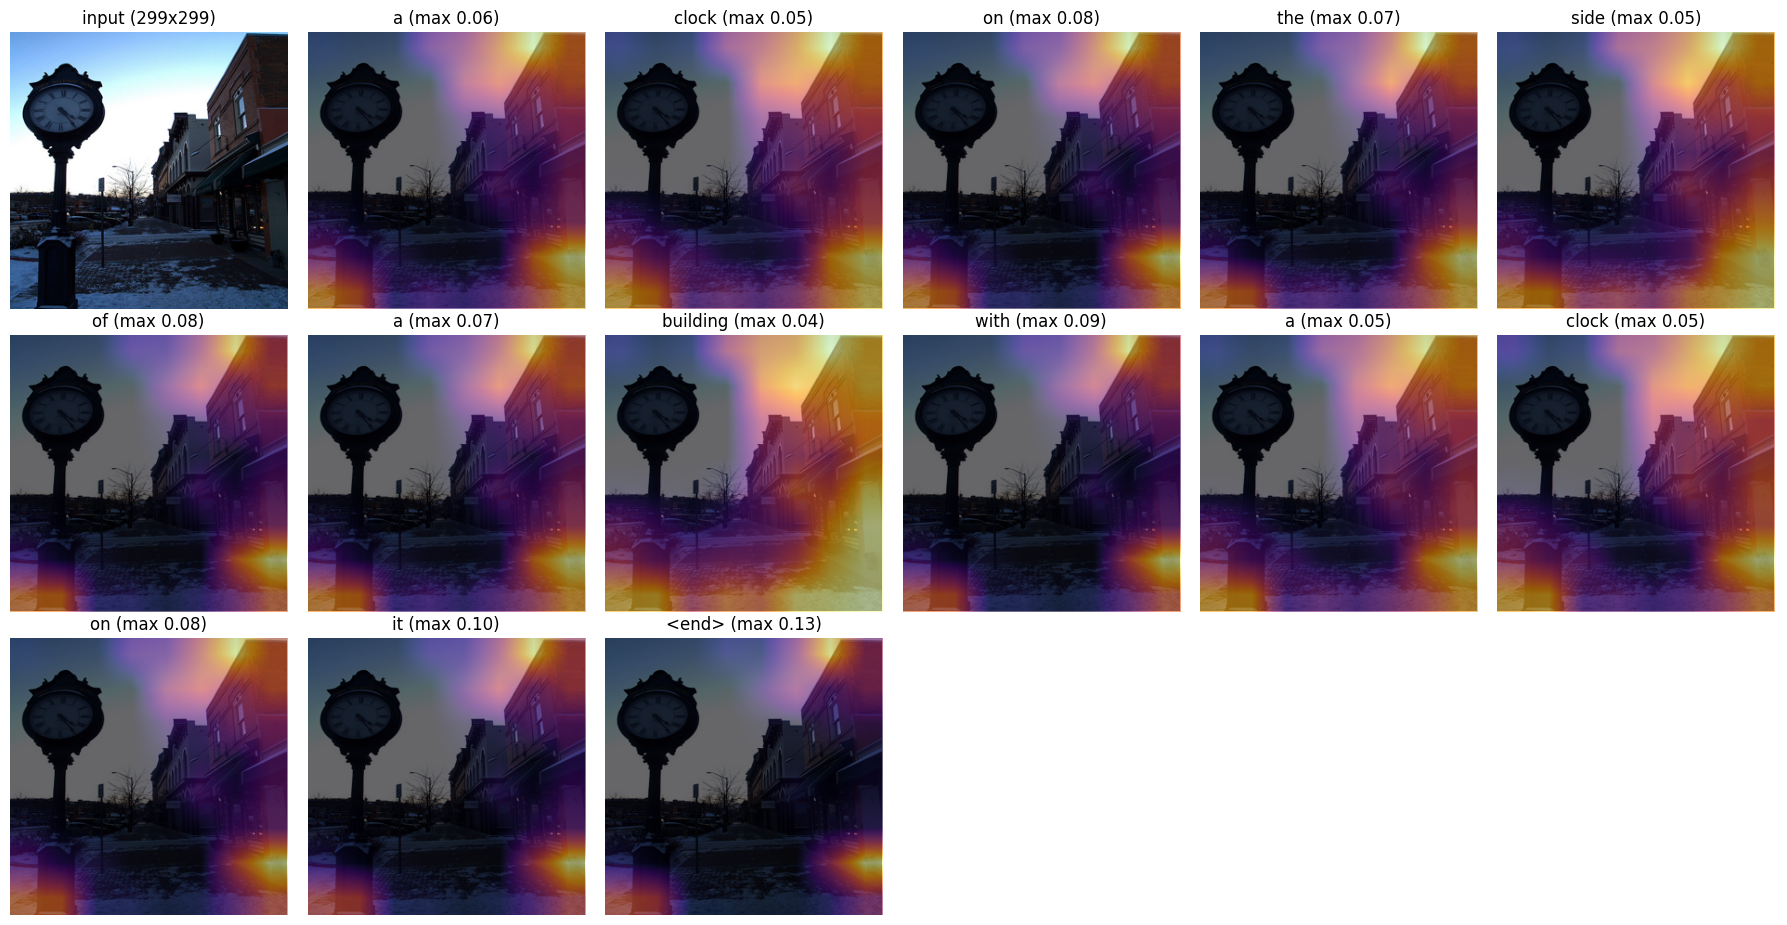

In [16]:
def show_attention(i):
    f = np.asarray(features["test"][i:i + 1], dtype=np.float32)
    _, scores = captioner_attention.predict_on_batch([f, test_sequences[i:i + 1]])   # (1, heads=1, 21, 64)
    words = (test_captions[i] + [END])[:MAX_LEN - 1]   # no <end> if the caption reached the maximum length
    img = np.asarray(Image.open(paths["test"][i]).convert("RGB").resize((CAPTION_IMG_SIZE, CAPTION_IMG_SIZE)))
    n_cols = 6
    n_rows = int(np.ceil((len(words) + 1) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3.1 * n_rows))
    axes = axes.ravel()
    axes[0].imshow(img); axes[0].set_title("input (299x299)")
    for t, word in enumerate(words):
        # Position t predicts word t: its weights are the 64 weights used to choose this word.
        weights = scores[0, 0, t].reshape(8, 8)
        axes[t + 1].imshow(img)
        axes[t + 1].imshow(weights, cmap="inferno", alpha=0.6, extent=(0, CAPTION_IMG_SIZE, CAPTION_IMG_SIZE, 0),
                           interpolation="bilinear")
        axes[t + 1].set_title(f"{word} (max {weights.max():.2f})")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


show_attention(shown[0])

**Reading: the attention is diffuse, and this is a limit of our model.** With 64 regions, a uniform spread would give 0.016 per region; the highest weight of a word is between 0.04 and 0.13, so the model barely concentrates. The bright areas (the sky at the top right and the ground at the bottom right) stay almost the same for every word and do not follow the clock, even for the word "clock" (each panel has its own colour scale, so the contrast exaggerates small differences). The word choice probably comes mostly from the image summary given as the first state of the GRU and from the language learned on the captions. We did not measure what the attention adds (a model without it, trained the same way, would answer this); section 11 lists it as the first check to make.

## 10. The whole workflow: D1, then D2, then D3

The final system receives scans of any kind. Each image goes through the three models:

1. **D1, photo or not** (`models/final_pretrained.keras`, MobileNetV2 fine-tuned, input 128x128, pixels in [0, 255]). Images under 0.5 are not photographs: they stop here.
2. **D2, denoising** (`models/d2_unet_multi_*.weights.h5`, the U-Net trained on several noise levels, section 8 of D2). The U-Net is fully convolutional, so its weights work at any size divisible by 8: we apply it at **304x304** instead of 128x128, which keeps the resolution that captioning needs (denoising at 128 and enlarging to 299 would lose most of the details). This is an assumption to check: D2 was trained on photos reduced to 128x128.
3. **D3, captioning**, resize to 299x299 and the model of this notebook.

The trained weights of D1 and D2 are not versioned. Put them in `models/` (see the README) to run this section; without them the cells only say what is missing.

**Images used.** `data/demo/` if it exists (the place for the unseen dataset of the defense: any images, any folder structure); otherwise 2 test images of each class of the D1 dataset (`data/Datasets`, same split as D1); otherwise 8 COCO test images.

In [17]:
from src.config import DATA_DIR, MANIFEST_PATH, NOISE_STD
from src.data import add_noise, list_image_paths

D1_PATH = MODELS / "final_pretrained.keras"
D2_SAVED = sorted(MODELS.glob("d2_unet_multi_[0-9]*.weights.h5"))
DENOISE_SIZE = 304   # multiple of 8 (3 poolings in the U-Net), close to 299
missing = ([] if D1_PATH.exists() else [str(D1_PATH)]) + ([] if D2_SAVED else ["models/d2_unet_multi_<date>.weights.h5"])
WORKFLOW_READY = not missing
print("Workflow ready." if WORKFLOW_READY else f"Section 10 skipped, missing: {', '.join(missing)}")


def build_unet_any_size():
    # The U-Net of D2 (same layers in the same order, see build_unet in deliverable2.ipynb), any input size.
    inputs = keras.Input((None, None, 3))
    c1 = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = keras.layers.MaxPooling2D(2)(c1)
    c2 = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = keras.layers.MaxPooling2D(2)(c2)
    c3 = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = keras.layers.MaxPooling2D(2)(c3)
    x = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)
    x = keras.layers.Concatenate()([x, c3])
    x = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)
    x = keras.layers.Concatenate()([x, c2])
    x = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)
    x = keras.layers.Concatenate()([x, c1])
    outputs = keras.layers.Conv2D(3, 3, padding="same", activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="unet_any_size")


if WORKFLOW_READY:
    photo_classifier = keras.models.load_model(D1_PATH)
    denoiser = build_unet_any_size()
    denoiser.load_weights(D2_SAVED[-1])
    print(f"D1: {D1_PATH.name} ({photo_classifier.count_params():,} parameters) | "
          f"D2: {D2_SAVED[-1].name} ({denoiser.count_params():,} parameters)")

Section 10 skipped, missing: models/final_pretrained.keras, models/d2_unet_multi_<date>.weights.h5


In [18]:
def is_photo_proba(pixels_u8):
    # D1: same input as in deliverable1.ipynb (PIL bilinear resize to 128x128, values in [0, 255]).
    x = np.stack([np.asarray(Image.fromarray(p).resize((128, 128), Image.BILINEAR), np.float32) for p in pixels_u8])
    return photo_classifier.predict_on_batch(x).ravel()


def to_size(x01, size):
    return tf.image.resize(x01, [size, size], antialias=True).numpy()


def denoise(x01, chunk=2):
    # D2 at DENOISE_SIZE: (n, DENOISE_SIZE, DENOISE_SIZE, 3) in [0, 1] -> same shape.
    # 2 images at a time: at 304x304 the U-Net activations of larger batches do not fit a 2 GB GPU.
    return np.clip(np.concatenate([denoiser.predict_on_batch(x01[s:s + chunk]) for s in range(0, len(x01), chunk)]), 0, 1)


def caption_pixels(x01):
    # D3 on images in [0, 1] of any size: resize to 299, scale to [-1, 1], InceptionV3, greedy decoding.
    f = inception_features(to_size(x01, CAPTION_IMG_SIZE) * 2.0 - 1.0).numpy()
    return [" ".join(c) for c in generate(f)[0]]


def load_u8(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB"))


if WORKFLOW_READY:
    demo_dir = Path("data/demo")
    if demo_dir.exists():
        demo_paths, demo_source = list_image_paths(demo_dir), "data/demo"
    elif Path(DATA_DIR).exists():
        manifest = pd.read_csv(MANIFEST_PATH)
        test_rows = manifest[(manifest["split"] == "test") & manifest["drop_reason"].isna()]
        chosen = test_rows.groupby("origin").sample(2, random_state=SEED)
        demo_paths, demo_source = [str(Path(DATA_DIR) / p) for p in chosen["path"]], "D1 test set, 2 per class"
    else:
        demo_paths, demo_source = paths["test"][:8], "COCO test images"
    print(f"{len(demo_paths)} images from {demo_source}")

    rows, shown_images = [], []
    for path in demo_paths:
        u8 = load_u8(path)
        p_photo = float(is_photo_proba([u8])[0])
        row = {"image": Path(path).name, "P(photo) (D1)": round(p_photo, 3), "decision": "photo" if p_photo >= 0.5 else "not a photo: stop"}
        x = to_size(u8[None].astype(np.float32) / 255.0, DENOISE_SIZE)
        if p_photo >= 0.5:
            clean_x = denoise(x)
            row["caption without D2"] = caption_pixels(x)[0]
            row["caption after D2 (D3)"] = caption_pixels(clean_x)[0]
            shown_images.append((u8, clean_x[0], row))
        rows.append(row)
    with pd.option_context("display.max_colwidth", None):
        display(pd.DataFrame(rows).fillna(""))

In [19]:
if WORKFLOW_READY and shown_images:
    n = min(4, len(shown_images))
    fig, axes = plt.subplots(2, n, figsize=(4.5 * n, 9), squeeze=False)
    for j, (u8, denoised, row) in enumerate(shown_images[:n]):
        axes[0, j].imshow(u8); axes[0, j].set_title(f"input, P(photo) = {row['P(photo) (D1)']:.2f}", fontsize=9.5)
        axes[1, j].imshow(denoised); axes[1, j].set_title(f"after D2:\n{row['caption after D2 (D3)']}", fontsize=9.5, wrap=True)
    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### 10.1 Does denoising help captioning? (COCO test set)

The demo above shows that the steps chain together. To measure what D2 brings to D3, we add Gaussian noise to the 1,000 COCO test images (the noise of D2, fixed by seed, at 304x304) and caption them with and without denoising. We also caption the **clean** images after denoising, to measure what D2 costs when there is no noise (the question of the D2 case study), and check that D1 recognises the COCO test images as photographs (they all are).

In [20]:
def caption_test_set(noise_std=None, use_denoiser=False, batch_size=25):
    # Captions of the COCO test images: resize to DENOISE_SIZE, optional noise (fixed seed), optional D2.
    ds = tf.data.Dataset.from_tensor_slices(paths["test"]).map(
        lambda p: tf.image.resize(tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False),
                                  [DENOISE_SIZE, DENOISE_SIZE], antialias=True) / 255.0).batch(batch_size)
    caps = []
    for b, x in enumerate(ds):
        x = tf.clip_by_value(x, 0.0, 1.0)
        if noise_std:
            x = add_noise(x, noise_std, seed=tf.constant([SEED, b], tf.int64))
        x = x.numpy()
        if use_denoiser:
            x = denoise(x)
        caps += [c.split() for c in caption_pixels(x)]
    return caps


if WORKFLOW_READY:
    t0 = time.time()
    p_photo = np.concatenate([is_photo_proba([load_u8(p) for p in paths["test"][s:s + 50]])
                              for s in range(0, len(paths["test"]), 50)])
    print(f"D1 on the {len(p_photo)} COCO test photographs: {100 * (p_photo >= 0.5).mean():.1f} % classified as photos")

    conditions = {"clean": (None, False), "clean, then D2": (None, True)}
    for std in (NOISE_STD, 0.2):
        conditions[f"noise {std}, no denoising"] = (std, False)
        conditions[f"noise {std}, then D2"] = (std, True)
    workflow_rows = {}
    for name, (std, use_d2) in conditions.items():
        caps = caption_test_set(std, use_d2)
        workflow_rows[name] = {**corpus_bleu(references, caps),
                               "same caption as clean (%)": np.nan}
        workflow_rows[name]["_caps"] = caps
    clean_caps = workflow_rows["clean"]["_caps"]
    for name, row in workflow_rows.items():
        row["same caption as clean (%)"] = 100 * np.mean([a == b for a, b in zip(row.pop("_caps"), clean_caps)])
    workflow_table = pd.DataFrame(workflow_rows).T
    print(f"Done in {time.time() - t0:.0f} s. Images at {DENOISE_SIZE}x{DENOISE_SIZE}, then 299x299 for InceptionV3.")
    display(workflow_table.style.format({**{f"BLEU-{n}": "{:.3f}" for n in range(1, 5)},
                                         "same caption as clean (%)": "{:.1f}"}))

**Reading.** In our execution this section was **not run**: the weights of D1 and D2 are not on this machine (see the message above). The code was tested end to end with placeholder D1 and D2 models (random weights): the images go through the classifier, the U-Net at 304x304 and the captioning model without error, and the comparison table is produced. The numbers can only be read once the real weights are in `models/`. Things to check then: the share of COCO photos that D1 accepts (they are modern colour photos, different from the D1 photos), whether captions after D2 are closer to the clean captions than captions of the noisy images, and the cost of D2 on clean images.

## 11. Analysis, limits and improvements

*Numbers of our run (seed 42); if the model is trained again they must be read again.*

### 11.1 Analysis

**What works.** With a frozen InceptionV3, a 7.4-million-parameter CNN + GRU decoder and 12,000 training images, the model writes grammatical captions that name the main object or scene in most test images (6 of the 8 random examples). On the 1,000 test images it reaches BLEU-4 0.179, almost twice the retrieval baseline (0.097) and not far from the agreement between two humans (0.204). Training is short: 7 epochs of about 65 s on a 2 GB GPU, after a feature extraction of about 3 minutes.

**Bias and variance.** The curves show overfitting from epoch 5 (validation loss up, training loss down). The model has more capacity than 12,000 images can fill; early stopping limits the damage but does not add information. The errors of section 9 (people instead of buffalo, skateboard instead of flying shoes, "a man" for everybody) are the other face of the same problem: with few examples of rare situations, the model falls back on the frequent ones.

**Pre-processing choices.** Computing the InceptionV3 features once is what makes the training possible on our machines (23 million frozen parameters not re-run at each epoch), at the price of 3.7 GB on disk in float16 (rounding error 2e-4, negligible). The vocabulary of 5,000 words covers 98.95 % of the word occurrences; the rest become `<unk>` and can never be written.

**A training failure, and what it taught.** The first training stalled at the level "always write *a*" because the `tanh` of the output was saturated by the large ImageNet features (measured: 100 % of its outputs at -1 or +1). Layer normalization and gradient clipping fixed it. The lesson for the oral: a curve that does not move from the first epoch is a bug or an instability, not a lack of epochs.

### 11.2 Limits

- **Data:** 12,000 of the 118,000 COCO training images (10 %), chosen for disk space and time. It is the main limit (section 11.1).
- **Domain:** COCO has modern colour photographs. TouNum archives are scans, often old and in black and white. We did not measure the captions on such images: it is the first thing to test with the client's data.
- **Metric:** BLEU only counts shared word sequences: it ignores synonyms and rewards common phrasing (section 8). METEOR and CIDEr, the other standard captioning scores, were not computed. A human check of a sample of captions would be the real test.
- **Attention:** diffuse in our model (section 9.2); we did not measure what it brings.
- **Greedy decoding:** repetitions, and no way to correct an early mistake.
- **One run:** a single training (seed 42); GPU computations are not exactly reproducible, so the third decimal of the scores is not meaningful.
- **Workflow:** section 10 was tested with placeholder models only; the effect of D2 on the captions is not measured yet. Denoising at 304x304 with a U-Net trained at 128x128 is an assumption.
- **Images squashed to 299x299** (no crop): a choice, the shapes in very wide images are distorted.

### 11.3 Improvements, by expected gain

1. **More images.** All of COCO train2017 (118,000 images): the overfitting of section 7 shows that data is the bottleneck. On disk it needs about 31 GB of float16 features; or features of a smaller size, or computed on the fly with a smaller CNN.
2. **Measure, then improve, the attention.** Train the same model without attention to know what it adds; if it adds little, use the "doubly stochastic" penalty of *Show, Attend and Tell* (Xu et al., 2015), which forces the model to look at every region over the sentence.
3. **Beam search** (keep the 3 to 5 best partial sentences instead of 1): fewer repetitions and usually +1 to +2 BLEU points, with no new training.
4. **Fine-tune the last blocks of InceptionV3** (as for MobileNetV2 in D1), or use a more recent encoder, once there are more images.
5. **More regularisation** (dropout on the embeddings, weight decay) to delay the overfitting.
6. **Evaluate on TouNum scans** (black and white, noisy) with the real D1 and D2 weights, which is what the client will use.